# 🎬 Classification de résumés de films — Horreur vs Comédie

**Projet :** Deep Learning — Create, Optimize, Push to Prod
**Auteur :** TheRealRPI
**Date :** 22/10/2026

---

## Objectif
Créer, optimiser et sauvegarder un modèle de classification binaire capable de prédire si un résumé de film est un film d'**horreur** ou une **comédie**, à partir de son texte.

## Plan du notebook (8 parties)
1. **Audit et nettoyage** — Explorer et nettoyer les données
2. **Découpage du jeu de données** — Train / Validation / Test / Production (60/20/20)
3. **Représentation du texte (TF-IDF)** — Vectorisation
4. **Les points de comparaison** — Modèles de référence (LogReg, NB, NN simple)
5. **Recherche des réglages avec KerasTuner** — RandomSearch (20 essais)
6. **Recherche des réglages avec Optuna** — Comparaison avec KerasTuner
7. **Verdict sur le test** — Évaluation finale
8. **Sauvegarde** — Export du modèle et des artefacts

---
## 📦 Imports

Toutes les bibliothèques nécessaires pour le projet.

In [2]:
# ─── Données & manipulation ───────────────────────────────────────────────
import json
import os
import platform

# ─── Utilitaires ──────────────────────────────────────────────────────────
import sys
from pathlib import Path

# ─── Sauvegarde ───────────────────────────────────────────────────────────
import joblib

# ─── KerasTuner : recherche d'hyperparamètres (partie 5) ──────────────────
import keras_tuner as kt

# ─── Visualisation ────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import numpy as np

# ─── Optuna : recherche d'hyperparamètres (partie 6) ──────────────────────
import optuna
import pandas as pd

# ─── TensorFlow / Keras : deep learning ───────────────────────────────────
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# ─── Scikit-learn : prétraitement, modèles classiques, métriques ─────────
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

# ─── Configuration ────────────────────────────────────────────────────────
# Pour éviter les messages d'avertissement de Tensor
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# Graines pour la reproductibilité
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Vérification du GPU
print(f"TensorFlow version : {tf.__version__}")
print(f"GPU disponible : {len(tf.config.list_physical_devices('GPU')) > 0}")
if len(tf.config.list_physical_devices("GPU")) > 0:
    print(f"GPU : {tf.config.list_physical_devices('GPU')}")

# Chemins
DATA_PATH = Path("./Data/textes_films_horreur_comedie.csv")
MODEL_DIR = Path("./model")
MODEL_DIR.mkdir(exist_ok=True)  # Création du dossier s'il n'existe pas

TensorFlow version : 2.21.0
GPU disponible : True
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## 1️⃣ Audit et nettoyage

**Objectif :** Charger le fichier, compter les lignes et les films de chaque catégorie, regarder la longueur des textes, supprimer les espaces en trop et les doublons.

**À noter en une phrase :** ce que vous avez trouvé et ce que vous avez corrigé.

In [3]:
# Chargement des données
df = pd.read_csv(DATA_PATH)
print(f"Nombre de lignes : {len(df)}")
print(f"Colonnes : {list(df.columns)}")
df.head()

Nombre de lignes : 2400
Colonnes : ['titre', 'resume', 'cible']


,titre,resume,cible
0,Chiedo asilo,Roberto has a new job as the teacher at a nurs...,0
1,Friday the 13th: A New Beginning,Five years after killing the goalie hockey-mas...,1
2,Stranger Than Fiction,Everybody knows that your life is a story. But...,0
3,Paris,"Pierre, a professional dancer, suffers from a ...",0
4,Sleepless,A retired detective with insomnia is called up...,1


Répartition des catégories :
cible
0 : comédie    1200
1 : horreur    1200
Name: count, dtype: int64


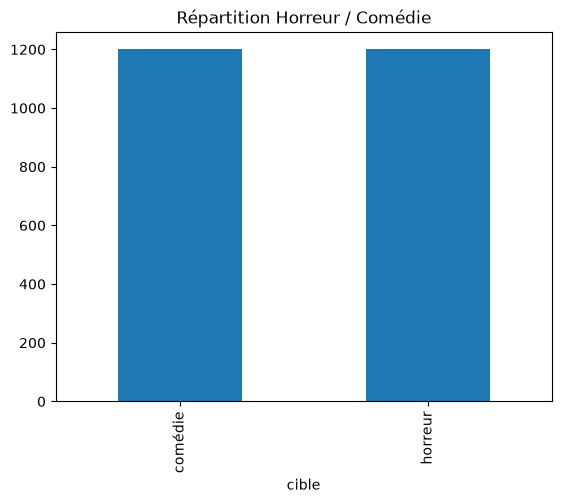

In [4]:
# Répartition des catégories
print("Répartition des catégories :")
print(df["cible"].map({0: "0 : comédie", 1: "1 : horreur"}).value_counts())

# Visualisation
df["cible"].map({0: "comédie", 1: "horreur"}).value_counts().plot(
    kind="bar", title="Répartition Horreur / Comédie"
)
plt.show()

count    2400.000000
mean       96.701667
std        61.264467
min        30.000000
25%        59.000000
50%        82.000000
75%       117.000000
max      1287.000000
Name: nb_mots, dtype: float64


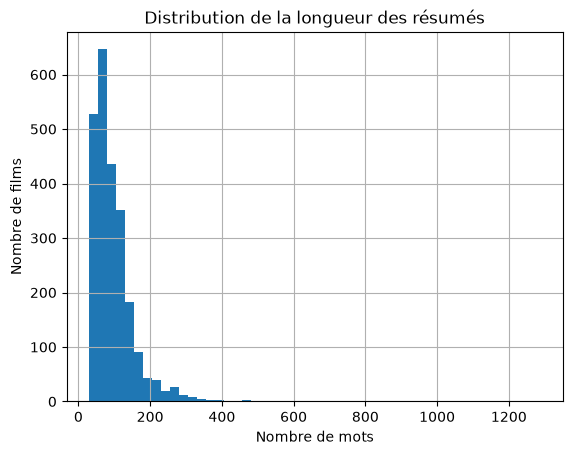

In [5]:
# Longueur des textes (en nombre de mots)
# Adapter le nom de la colonne resume selon le CSV
colonne_resume = "resume"
df["nb_mots"] = df[colonne_resume].astype(str).apply(lambda x: len(x.split()))

print(df["nb_mots"].describe())

# Visualisation de la distribution
df["nb_mots"].hist(bins=50)
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de films")
plt.title("Distribution de la longueur des résumés")
plt.show()

In [6]:
# Nettoyage : suppression des espaces en trop et des doublons
nb_avant = len(df)

# Suppression des espaces en début/fin et normalisation des espaces multiples
df[colonne_resume] = df[colonne_resume].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

# Suppression des doublons (lignes identiques)
df = df.drop_duplicates()

# Suppression des doublons sur le texte uniquement (même résumé, catégorie différente = suspect)
df = df.drop_duplicates(subset=[colonne_resume])

nb_apres = len(df)
print(f"Lignes avant nettoyage : {nb_avant}")
print(f"Lignes après nettoyage : {nb_apres}")
print(f"Lignes supprimées : {nb_avant - nb_apres}")

Lignes avant nettoyage : 2400
Lignes après nettoyage : 2346
Lignes supprimées : 54


In [7]:
# Vérification de la répartition après nettoyage
print("\nRépartition après nettoyage :")
print(df["cible"].map({0: "0 : comédie", 1: "1 : horreur"}).value_counts())


Répartition après nettoyage :
cible
0 : comédie    1195
1 : horreur    1151
Name: count, dtype: int64


### 📝 Note d'audit

> *À compléter : en une phrase, ce que vous avez trouvé et ce que vous avez corrigé.*

> Le jeu de données initial contient 2400 lignes réparties en 1200 horreur(1) et 1200 comédie(0) . Après nettoyage, on a supprimé 54 doublons et normalisé les espaces. Les textes font en moyenne ~97 mots.

> Le jeu de données final contient 2346 lignes réparties en 1195 comédie pour 1151 films d'horreurs.


---
## 2️⃣ Découpage du jeu de données

**Objectif :** Séparer les textes en trois parties :
- **60 %** apprentissage (train)
- **20 %** test
- **20 %** production (à garder de côté, on n'y touche pas)

Garder la même proportion d'horreur et de comédie dans chaque partie (`stratify`).

In [11]:
# Séparation des features (X) et de la cible (y)
colonne_texte = "resume"
colonne_label = "cible"

X = df[colonne_texte]
y = df[colonne_label]

# Premier split : 80% (train+val) / 20% (test)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# Deuxième split : 75% de temp = 60% du total (train) / 25% de temp = 20% du total (production)
X_train, X_prod, y_train, y_prod = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=SEED, stratify=y_temp
)

In [15]:
print(f"Train      : {len(X_train)} ({len(X_train) / len(df):.1%})")
print(f"Test       : {len(X_test)} ({len(X_test) / len(df):.1%})")
print(f"Production : {len(X_prod)} ({len(X_prod) / len(df):.1%})")

# Vérification de la stratification
print("\nProportions exactes :")
print(f"  Train      : {y_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"  Test       : {y_test.value_counts(normalize=True).round(3).to_dict()}")
print(f"  Production : {y_prod.value_counts(normalize=True).round(3).to_dict()}")

Train      : 1407 (60.0%)
Test       : 470 (20.0%)
Production : 469 (20.0%)

Proportions exactes :
  Train      : {0: 0.51, 1: 0.49}
  Test       : {0: 0.509, 1: 0.491}
  Production : {0: 0.51, 1: 0.49}


---
## 3️⃣ Représentation du texte (TF-IDF)

**Objectif :** Transformer chaque texte en nombres avec un TF-IDF.

⚠️ **Important :** Apprendre le vocabulaire sur l'**apprentissage seulement**, puis transformer les trois parties avec ce même objet.

In [ ]:
# Création et ajustement du vectoriseur TF-IDF sur le train uniquement
vectoriseur = TfidfVectorizer(
    max_features=4242,  # Limite du vocabulaire
    ngram_range=(
        1,
        2,
    ),  # Unigrammes et bigrammes. Les bigrammes capturent du contexte que les mots isolés perdent.
    min_df=2,  # Ignore les termes présents dans moins de 2 documents
    max_df=0.95,  # Ignore les termes présents dans plus de 95% des documents
    stop_words="english",  # Liste de stopwords anglais de scikit-learn (the, and, is, ...) (pas de stop words français par défaut)
)

# Apprentissage sur le train uniquement
X_train_tfidf = vectoriseur.fit_transform(X_train)

# Transformation des autres parties avec le même vectoriseur
X_test_tfidf = vectoriseur.transform(X_test)
X_prod_tfidf = vectoriseur.transform(X_prod)

print(f"Dimensions train : {X_train_tfidf.shape}")
print(f"Dimensions test  : {X_test_tfidf.shape}")
print(f"Vocabulaire     : {len(vectoriseur.vocabulary_)} termes")

In [ ]:
# Conversion en tableaux denses pour Keras (si nécessaire)
# Note : pour les réseaux de neurones, on utilisera les vecteurs TF-IDF en entrée
X_train_dense = X_train_tfidf.toarray()
X_test_dense = X_test_tfidf.toarray()
X_prod_dense = X_prod_tfidf.toarray()

print(f"Dimensions denses train : {X_train_dense.shape}")
print(f"Type : {X_train_dense.dtype}")

---
## 4️⃣ Les points de comparaison

**Objectif :** Entraîner trois modèles et mesurer le F1 de chacun sur **5 graines différentes**.

| Modèle | Description |
|--------|-------------|
| Régression logistique | Modèle linéaire de référence |
| Bayes naïf (MultinomialNB) | Modèle probabiliste de référence |
| Réseau de neurones simple | 1 couche cachée, un peu de dropout, aucun réglage particulier |

**Marge de bruit :** `1,96 × √(p(1-p)/n)` avec `p` = score F1 et `n` = taille de l'échantillon de validation.

In [ ]:
# Fonction pour calculer la marge de bruit
def marge_de_bruit(p: float, n: int) -> float:
    """Calcule la marge de bruit à 95% pour un score F1."""
    return 1.96 * np.sqrt(p * (1 - p) / n)


# Split train/validation pour évaluer les modèles (80/20 du train)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_tfidf, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)

n_val = X_val.shape[0]
print(f"Taille validation : {n_val}")

In [ ]:
# ─── Modèle 1 : Régression logistique ─────────────────────────────────────
SEEDS = [42, 123, 456, 789, 2024]
results = {"LogReg": [], "MultinomialNB": [], "NN_simple": []}

for seed in SEEDS:
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Régression logistique
    logreg = LogisticRegression(max_iter=1000, random_state=seed)
    logreg.fit(X_tr, y_tr)
    y_pred_lr = logreg.predict(X_val)
    f1_lr = f1_score(y_val, y_pred_lr)
    results["LogReg"].append(f1_lr)

    # Bayes naïf
    nb = MultinomialNB()
    nb.fit(X_tr, y_tr)
    y_pred_nb = nb.predict(X_val)
    f1_nb = f1_score(y_val, y_pred_nb)
    results["MultinomialNB"].append(f1_nb)

print("F1 scores sur 5 graines :")
for model, scores in results.items():
    print(f"  {model:15s} : {np.mean(scores):.4f} ± {np.std(scores):.4f}  {scores}")

In [ ]:
# ─── Modèle 3 : Réseau de neurones simple ─────────────────────────────────
def creer_nn_simple(input_dim: int, seed: int = SEED):
    """Réseau de départ très simple : 1 couche cachée, un peu de dropout."""
    tf.random.set_seed(seed)
    modele = keras.Sequential(
        [
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(1, activation="sigmoid"),
        ]
    )
    modele.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modele


# Conversion en dense pour Keras
X_tr_dense = X_tr.toarray()
X_val_dense = X_val.toarray()

input_dim = X_tr_dense.shape[1]

for seed in SEEDS:
    np.random.seed(seed)
    tf.random.set_seed(seed)

    modele = creer_nn_simple(input_dim, seed)
    modele.fit(
        X_tr_dense,
        y_tr,
        epochs=20,
        batch_size=32,
        validation_data=(X_val_dense, y_val),
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0,
    )

    y_pred_proba = modele.predict(X_val_dense, verbose=0)
    y_pred_nn = (y_pred_proba > 0.5).astype(int).flatten()
    f1_nn = f1_score(y_val, y_pred_nn)
    results["NN_simple"].append(f1_nn)

print("\nF1 scores finaux sur 5 graines :")
for model, scores in results.items():
    moyenne = np.mean(scores)
    print(f"  {model:15s} : {moyenne:.4f} ± {np.std(scores):.4f}  {scores}")
    print(f"    Marge de bruit (n={n_val}) : ±{marge_de_bruit(moyenne, n_val):.4f}")

---
## 5️⃣ Recherche des réglages avec KerasTuner

**Objectif :** Écrire une fonction qui construit un réseau à partir de **cinq réglages** :
- Nombre de couches
- Nombre de neurones
- Dropout
- Régularisation (L2)
- Taux d'apprentissage

Puis lancer **KerasTuner (RandomSearch, 20 essais)**.

In [ ]:
# Fonction de construction du modèle avec hyperparamètres réglables
def construire_modele(hp: kt.HyperParameters, input_dim: int):
    """Construit un réseau de neurones à partir des hyperparamètres."""
    modele = keras.Sequential()
    modele.add(layers.Input(shape=(input_dim,)))

    # Nombre de couches cachées (1 à 3)
    nb_couches = hp.Int("nb_couches", min_value=1, max_value=3, step=1)

    for i in range(nb_couches):
        # Nombre de neurones (décroissant)
        nb_neurones = hp.Int(f"neurones_{i}", min_value=32, max_value=256, step=32)

        # Régularisation L2
        l2 = hp.Float(f"l2_{i}", min_value=1e-5, max_value=1e-2, sampling="log")

        modele.add(
            layers.Dense(nb_neurones, activation="relu", kernel_regularizer=regularizers.l2(l2))
        )

        # Dropout
        dropout = hp.Float(f"dropout_{i}", min_value=0.0, max_value=0.5, step=0.1)
        modele.add(layers.Dropout(dropout))

    # Couche de sortie
    modele.add(layers.Dense(1, activation="sigmoid"))

    # Taux d'apprentissage
    lr = hp.Float("learning_rate", min_value=1e-4, max_value=1e-2, sampling="log")

    modele.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    return modele

In [ ]:
# Lancement de la recherche KerasTuner (RandomSearch, 20 essais)
tuner = kt.RandomSearch(
    lambda hp: construire_modele(hp, input_dim),
    objective="val_accuracy",
    max_trials=20,
    executions_per_trial=1,
    directory="keras_tuner_dir",
    project_name="classification_films",
    overwrite=True,  # Écrase les essais précédents (évite errno 22 sous Windows)
)

# Recherche
tuner.search(
    X_tr_dense,
    y_tr,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_dense, y_val),
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
    verbose=1,
)

# Meilleurs hyperparamètres
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\nMeilleurs hyperparamètres (KerasTuner) :")
for param in ["nb_couches", "learning_rate"]:
    print(f"  {param}: {best_hps.get(param)}")
for i in range(best_hps.get("nb_couches")):
    print(
        f"  couche {i}: neurones={best_hps.get(f'neurones_{i}')}, "
        f"dropout={best_hps.get(f'dropout_{i}')}, l2={best_hps.get(f'l2_{i}')}"
    )

In [ ]:
# Évaluation du meilleur modèle KerasTuner sur la validation
best_model_kt = tuner.get_best_models(num_models=1)[0]

y_pred_kt = (best_model_kt.predict(X_val_dense, verbose=0) > 0.5).astype(int).flatten()
f1_kt = f1_score(y_val, y_pred_kt)

print(f"F1 KerasTuner (meilleur modèle) : {f1_kt:.4f}")
print(f"Marge de bruit : ±{marge_de_bruit(f1_kt, n_val):.4f}")

---
## 6️⃣ Recherche des réglages avec Optuna

**Objectif :** Refaire la même recherche avec **Optuna**, sur exactement les mêmes réglages, les mêmes valeurs possibles, le même nombre d'essais (20), en réutilisant la fonction `construire_modele`.

**Comparer** le meilleur score des deux outils, en tenant compte de la marge de bruit.

In [ ]:
# Fonction objective pour Optuna
def objective_optuna(trial):
    """Fonction à minimiser/maximiser par Optuna."""
    # Définition des hyperparamètres (mêmes plages que KerasTuner)
    nb_couches = trial.suggest_int("nb_couches", 1, 3, step=1)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)

    # Construction du modèle
    modele = keras.Sequential()
    modele.add(layers.Input(shape=(input_dim,)))

    for i in range(nb_couches):
        neurones = trial.suggest_int(f"neurones_{i}", 32, 256, step=32)
        l2 = trial.suggest_float(f"l2_{i}", 1e-5, 1e-2, log=True)
        dropout = trial.suggest_float(f"dropout_{i}", 0.0, 0.5, step=0.1)

        modele.add(
            layers.Dense(neurones, activation="relu", kernel_regularizer=regularizers.l2(l2))
        )
        modele.add(layers.Dropout(dropout))

    modele.add(layers.Dense(1, activation="sigmoid"))

    modele.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    # Entraînement
    history = modele.fit(
        X_tr_dense,
        y_tr,
        epochs=20,
        batch_size=32,
        validation_data=(X_val_dense, y_val),
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0,
    )

    # Retourne la meilleure val_accuracy
    return max(history.history["val_accuracy"])


# Création de l'étude Optuna
study = optuna.create_study(direction="maximize")
study.optimize(objective_optuna, n_trials=20, show_progress_bar=True)

In [ ]:
# Meilleurs hyperparamètres Optuna
print("Meilleurs hyperparamètres (Optuna) :")
best_params_optuna = study.best_params
for key, value in best_params_optuna.items():
    print(f"  {key}: {value}")

# Réentraînement du meilleur modèle Optuna pour obtenir le F1
# (reconstruction avec les meilleurs paramètres)
best_model_optuna = keras.Sequential()
best_model_optuna.add(layers.Input(shape=(input_dim,)))

for i in range(best_params_optuna["nb_couches"]):
    best_model_optuna.add(
        layers.Dense(
            best_params_optuna[f"neurones_{i}"],
            activation="relu",
            kernel_regularizer=regularizers.l2(best_params_optuna[f"l2_{i}"]),
        )
    )
    best_model_optuna.add(layers.Dropout(best_params_optuna[f"dropout_{i}"]))

best_model_optuna.add(layers.Dense(1, activation="sigmoid"))
best_model_optuna.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_params_optuna["learning_rate"]),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

best_model_optuna.fit(
    X_tr_dense,
    y_tr,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_dense, y_val),
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
    verbose=0,
)

y_pred_opt = (best_model_optuna.predict(X_val_dense, verbose=0) > 0.5).astype(int).flatten()
f1_opt = f1_score(y_val, y_pred_opt)

print(f"\nF1 Optuna (meilleur modèle) : {f1_opt:.4f}")
print(f"Marge de bruit : ±{marge_de_bruit(f1_opt, n_val):.4f}")

In [ ]:
# Comparaison KerasTuner vs Optuna
print("=" * 50)
print("COMPARAISON KerasTuner vs Optuna")
print("=" * 50)
print(f"KerasTuner  : F1 = {f1_kt:.4f} ± {marge_de_bruit(f1_kt, n_val):.4f}")
print(f"Optuna      : F1 = {f1_opt:.4f} ± {marge_de_bruit(f1_opt, n_val):.4f}")
print("-" * 50)

ecart = abs(f1_kt - f1_opt)
marge_max = max(marge_de_bruit(f1_kt, n_val), marge_de_bruit(f1_opt, n_val))

print(f"Écart absolu : {ecart:.4f}")
print(f"Marge de bruit max : {marge_max:.4f}")

if ecart < marge_max:
    print(
        "\n✅ L'écart est inférieur à la marge de bruit : on ne peut pas dire qu'un outil est meilleur que l'autre."
    )
else:
    meilleur = "KerasTuner" if f1_kt > f1_opt else "Optuna"
    print(f"\n✅ L'écart dépasse la marge de bruit : {meilleur} est significativement meilleur.")

---
## 7️⃣ Verdict sur le test

**Objectif :**
1. Prendre les meilleurs réglages (du meilleur outil)
2. Réentraîner le réseau sur **tout l'apprentissage** (train + validation)
3. Sur **5 graines**
4. Comparer avec le réseau de départ et le meilleur modèle simple
5. Mesurer sur le **test, une seule fois**
6. Conclure honnêtement

In [ ]:
# Fusion train + validation pour le réentraînement final
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

# Re-vectorisation sur le train complet
vectoriseur_full = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
)
X_train_full_tfidf = vectoriseur_full.fit_transform(X_train_full)
X_test_tfidf_full = vectoriseur_full.transform(X_test)

X_train_full_dense = X_train_full_tfidf.toarray()
X_test_dense_full = X_test_tfidf_full.toarray()

input_dim_full = X_train_full_dense.shape[1]
print(f"Dimensions train complet : {X_train_full_dense.shape}")
print(f"Dimensions test : {X_test_dense_full.shape}")

In [ ]:
# Réentraînement du meilleur modèle sur tout l'apprentissage, 5 graines
# Utiliser les meilleurs hyperparamètres trouvés (KerasTuner ou Optuna)

# Sélection des meilleurs hyperparamètres (à adapter selon le gagnant)
# Exemple avec Optuna (à remplacer si KerasTuner est meilleur)
best_hps_final = best_params_optuna  # ou best_hps de KerasTuner

f1_test_scores = []

for seed in SEEDS:
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Construction du modèle avec les meilleurs hyperparamètres
    modele = keras.Sequential()
    modele.add(layers.Input(shape=(input_dim_full,)))

    for i in range(best_hps_final["nb_couches"]):
        modele.add(
            layers.Dense(
                best_hps_final[f"neurones_{i}"],
                activation="relu",
                kernel_regularizer=regularizers.l2(best_hps_final[f"l2_{i}"]),
            )
        )
        modele.add(layers.Dropout(best_hps_final[f"dropout_{i}"]))

    modele.add(layers.Dense(1, activation="sigmoid"))
    modele.compile(
        optimizer=keras.optimizers.Adam(learning_rate=best_hps_final["learning_rate"]),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    # Entraînement sur tout le train
    modele.fit(
        X_train_full_dense,
        y_train_full,
        epochs=20,
        batch_size=32,
        callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
        verbose=0,
    )

    # Évaluation sur le test (une seule fois par graine)
    y_pred_test = (modele.predict(X_test_dense_full, verbose=0) > 0.5).astype(int).flatten()
    f1 = f1_score(y_test, y_pred_test)
    f1_test_scores.append(f1)
    print(f"  Graine {seed} : F1 test = {f1:.4f}")

f1_test_moyen = np.mean(f1_test_scores)
f1_test_std = np.std(f1_test_scores)
n_test = len(y_test)

print(f"\n{'=' * 50}")
print(f"RÉSULTAT FINAL SUR LE TEST")
print(f"{'=' * 50}")
print(f"F1 moyen : {f1_test_moyen:.4f} ± {f1_test_std:.4f}")
print(f"Scores   : {f1_test_scores}")
print(f"Marge de bruit (n={n_test}) : ±{marge_de_bruit(f1_test_moyen, n_test):.4f}")

In [ ]:
# Comparaison avec les modèles de référence (réentraînés sur tout le train)
print("Comparaison avec les modèles de référence :")

# Régression logistique
logreg_full = LogisticRegression(max_iter=1000, random_state=SEED)
logreg_full.fit(X_train_full_tfidf, y_train_full)
f1_logreg_test = f1_score(y_test, logreg_full.predict(X_test_tfidf_full))
print(f"  Régression logistique : F1 = {f1_logreg_test:.4f}")

# Bayes naïf
nb_full = MultinomialNB()
nb_full.fit(X_train_full_tfidf, y_train_full)
f1_nb_test = f1_score(y_test, nb_full.predict(X_test_tfidf_full))
print(f"  Bayes naïf            : F1 = {f1_nb_test:.4f}")

# Réseau optimisé
print(f"  Réseau optimisé       : F1 = {f1_test_moyen:.4f}")

# Marge de bruit
marge = marge_de_bruit(f1_test_moyen, n_test)
print(f"\n  Marge de bruit : ±{marge:.4f}")

# Conclusion
print("\n" + "=" * 50)
print("CONCLUSION")
print("=" * 50)

meilleur_simple = max(f1_logreg_test, f1_nb_test)
if f1_test_moyen - meilleur_simple > marge:
    print(f"✅ Le réseau optimisé ({f1_test_moyen:.4f}) est significativement")
    print(f"   meilleur que le meilleur modèle simple ({meilleur_simple:.4f}).")
elif abs(f1_test_moyen - meilleur_simple) <= marge:
    print(f"⚠️  L'écart entre le réseau optimisé ({f1_test_moyen:.4f}) et le")
    print(f"   meilleur modèle simple ({meilleur_simple:.4f}) est inférieur à la marge de bruit.")
    print(f"   On ne peut pas conclure que le réseau est meilleur.")
else:
    print(f"❌ Le réseau optimisé ({f1_test_moyen:.4f}) n'est pas meilleur")
    print(f"   que le meilleur modèle simple ({meilleur_simple:.4f}).")

---
## 8️⃣ Sauvegarde

**Objectif :** Créer un dossier `model/` et y ranger :
- `model.keras` — le réseau au format `.keras`
- `vectoriseur.joblib` — le TF-IDF avec joblib
- `metrics.json` — version du modèle, F1 obtenu sur le test, taille du test, versions des bibliothèques (UTF-8)
- `reference.csv` — un petit échantillon de données de référence

In [ ]:
# Réentraînement final du meilleur modèle (graine fixe pour la sauvegarde)
np.random.seed(SEED)
tf.random.set_seed(SEED)

modele_final = keras.Sequential()
modele_final.add(layers.Input(shape=(input_dim_full,)))

for i in range(best_hps_final["nb_couches"]):
    modele_final.add(
        layers.Dense(
            best_hps_final[f"neurones_{i}"],
            activation="relu",
            kernel_regularizer=regularizers.l2(best_hps_final[f"l2_{i}"]),
        )
    )
    modele_final.add(layers.Dropout(best_hps_final[f"dropout_{i}"]))

modele_final.add(layers.Dense(1, activation="sigmoid"))
modele_final.compile(
    optimizer=keras.optimizers.Adam(learning_rate=best_hps_final["learning_rate"]),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

modele_final.fit(
    X_train_full_dense,
    y_train_full,
    epochs=20,
    batch_size=32,
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
    verbose=1,
)

# Évaluation finale sur le test
y_pred_final = (modele_final.predict(X_test_dense_full, verbose=0) > 0.5).astype(int).flatten()
f1_final = f1_score(y_test, y_pred_final)
print(f"\nF1 final sur le test : {f1_final:.4f}")

In [ ]:
# Sauvegarde du modèle
modele_final.save(MODEL_DIR / "model.keras")
print(f"✅ Modèle sauvegardé : {MODEL_DIR / 'model.keras'}")

# Sauvegarde du vectoriseur
joblib.dump(vectoriseur_full, MODEL_DIR / "vectoriseur.joblib")
print(f"✅ Vectoriseur sauvegardé : {MODEL_DIR / 'vectoriseur.joblib'}")

In [ ]:
# Création du fichier metrics.json
metrics = {
    "model_version": "1.0.0",
    "model_type": "Sequential (Keras)",
    "f1_score_test": round(float(f1_final), 4),
    "f1_score_test_moyen_5_graines": round(float(f1_test_moyen), 4),
    "f1_score_test_std_5_graines": round(float(f1_test_std), 4),
    "test_size": int(n_test),
    "train_size": int(len(y_train_full)),
    "production_size": int(len(y_prod)),
    "marge_de_bruit": round(float(marge_de_bruit(f1_final, n_test)), 4),
    "meilleurs_hyperparametres": {
        k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in best_hps_final.items()
    },
    "vectoriseur": {
        "type": "TfidfVectorizer",
        "max_features": 10000,
        "ngram_range": [1, 2],
        "vocabulaire_size": len(vectoriseur_full.vocabulary_),
    },
    "bibliotheques": {
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "keras_tuner": keras_tuner.__version__,
        "optuna": optuna.__version__,
        "joblib": joblib.__version__,
    },
    "date_entrainement": "2026-10-22",
    "seed": SEED,
}

with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print(f"✅ Métriques sauvegardées : {MODEL_DIR / 'metrics.json'}")
print(json.dumps(metrics, indent=2, ensure_ascii=False))

In [ ]:
# Création d'un échantillon de référence (10 exemples par classe)
reference = pd.DataFrame(
    {
        colonne_texte: pd.concat([X_test, X_prod]).reset_index(drop=True),
        "label": pd.concat([y_test, y_prod]).reset_index(drop=True),
    }
)

# 10 exemples par classe
reference_sample = reference.groupby("label").head(10).reset_index(drop=True)

reference_sample.to_csv(MODEL_DIR / "reference.csv", index=False, encoding="utf-8")
print(f"✅ Référence sauvegardée : {MODEL_DIR / 'reference.csv'} ({len(reference_sample)} lignes)")
reference_sample.head()

In [ ]:
# Vérification finale du dossier model/
print("Contenu du dossier model/ :")
for fichier in sorted(MODEL_DIR.iterdir()):
    taille = fichier.stat().st_size / 1024  # en Ko
    print(f"  📄 {fichier.name:25s} ({taille:.1f} Ko)")

---
## ✅ Fin du notebook

Le notebook s'est exécuté de haut en bas sans erreur. Le dossier `model/` contient :
- `model.keras` — le réseau entraîné
- `vectoriseur.joblib` — le TF-IDF
- `metrics.json` — les métriques et métadonnées
- `reference.csv` — un échantillon de données de référence

**Prochaine étape :** Partie 2 — L'API FastAPI